Attention

与传统的 Transformer 注意力机制不同，这里融合了当前大模型最前沿的几种优化技术：GQA（分组查询注意力）、KV-Cache、RoPE 以及 Flash Attention。

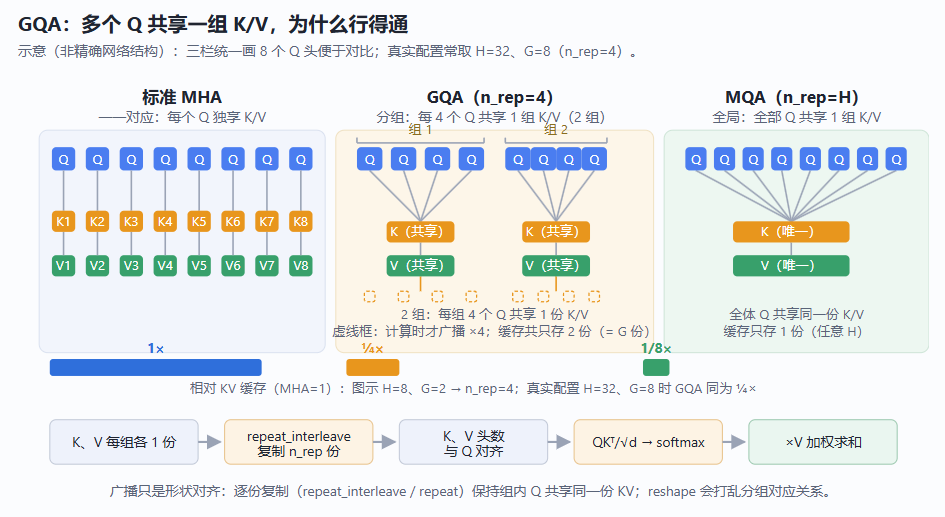

In [ ]:
import torch
import torch.nn as nn
import math
###这段代码就是你kv不是共享么，但是你去qk进行计算的时候要临时先复制一份对齐，然后算完之后就扔掉了！！！
def repeat_kv(x : torch.Tensor, n_rep) -> torch.Tensor:
    # x 形状为 (bs, seq_len, num_kv_heads, head_dim)
    bs, seq_len, num_kv_heads, head_dim = x.shape
    if n_rep == 1: return x
    return x[:, :, :, None, :].expand(bs, seq_len, num_kv_heads, n_rep, head_dim).reshape(bs, seq_len, n_rep * num_kv_heads, -1)

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import PretrainedConfig, PreTrainedModel, GenerationMixin


class MiniMindConfig(PretrainedConfig):
    model_type = "minimind"
    def __init__(self, hidden_size=768, num_hidden_layers=8, use_moe=False, **kwargs):
        super().__init__(**kwargs)
        self.hidden_size = hidden_size
        self.num_hidden_layers = num_hidden_layers
        self.use_moe = use_moe
        self.dropout = kwargs.get("dropout", 0.0)
        self.vocab_size = kwargs.get("vocab_size", 6400)
        self.bos_token_id = kwargs.get("bos_token_id", 1)
        self.eos_token_id = kwargs.get("eos_token_id", 2)
        self.flash_attn = kwargs.get("flash_attn", True)
        self.num_attention_heads = kwargs.get("num_attention_heads", 8)
        self.num_key_value_heads = kwargs.get("num_key_value_heads", 4)
        self.head_dim = kwargs.get("head_dim", self.hidden_size // self.num_attention_heads)
        self.hidden_act = kwargs.get("hidden_act", 'silu')
        self.intermediate_size = kwargs.get("intermediate_size", math.ceil(hidden_size * math.pi / 64) * 64)
        self.max_position_embeddings = kwargs.get("max_position_embeddings", 32768)
        self.rms_norm_eps = kwargs.get("rms_norm_eps", 1e-6)
        self.rope_theta = kwargs.get("rope_theta", 1e6)
        self.tie_word_embeddings = kwargs.get("tie_word_embeddings", True)
        self.inference_rope_scaling = kwargs.get("inference_rope_scaling", False)
        self.rope_scaling = {
            "beta_fast": 32,
            "beta_slow": 1,
            "factor": 16,
            "original_max_position_embeddings": 2048,
            "attention_factor": 1.0,
            "type": "yarn"
        } if self.inference_rope_scaling else None
        ### MoE specific configs (ignored if use_moe = False)
        self.num_experts = kwargs.get("num_experts", 4)
        self.num_experts_per_tok = kwargs.get("num_experts_per_tok", 1)
        self.moe_intermediate_size = kwargs.get("moe_intermediate_size", self.intermediate_size)
        self.norm_topk_prob = kwargs.get("norm_topk_prob", True)
        self.router_aux_loss_coef = kwargs.get("router_aux_loss_coef", 5e-4)




In [ ]:

class Attention(nn.Module):
    def __init__(self, config : MiniMindConfig):
        super().__init__()
        # 每个token的维度：768
        self.hidden_dim : int = config.hidden_size
        # q的头数，这里取的是8
        self.num_q_heads: int = config.num_attention_heads
        # kv的头数，这里取的是4
        self.num_kv_heads : int = config.num_key_value_heads
        # 每个头的维度 也就是768/8=96
        self.head_dim: int = config.head_dim
        # 是否启用"因果掩码"：每个 token 只能看自己和左边，不能看右边（未来）。 
        self.is_causal = True
        # 每个 KV 头要被复制 n_rep 份，服务 n_rep 个 Q 头
        # 8/4 = 2 → 1 个 KV 头对应 2 个 Q 头（共 4 个 KV 头，覆盖 8 个 Q 头）
        self.n_rep = self.num_q_heads // self.num_kv_heads
        # wq，其实就是768->8*96    这里偏置设置为Flase就是不使用偏置，在rope中有r了，这里的偏置使用效果没有很好的提升了
        self.proj_q = nn.Linear(config.hidden_size, self.num_q_heads * self.head_dim, bias = False)
        # wk，其实就是768->4*96
        self.proj_k = nn.Linear(config.hidden_size, self.num_kv_heads * self.head_dim, bias = False)
        # wv，其实就是768->4*96
        self.proj_v = nn.Linear(config.hidden_size, self.num_kv_heads * self.head_dim, bias = False)
        # 这个o矩阵就是你多头注意力机制算完cat后在经过一个大的w矩阵，768->768
        self.proj_o = nn.Linear(config.hidden_size, config.hidden_size, bias = False)
        # 这个使用的是RMSNorm归一化，参考1_RMSNorm.ipynb,为什么 v 不归一化？ v 不参与点积、不产生分数，它是被加权求和的内容；归一化会强行改变它的尺度，破坏语义。
        self.q_norm = RMSNorm(self.head_dim, eps = config.rms_norm_eps)
        self.k_norm = RMSNorm(self.head_dim, eps = config.rms_norm_eps)
        # 这里就是作用在注意力概率上，在 softmax 之后、@ Xv 之前——随机丢掉某些 token 的权重。
        self.attn_dropout = nn.Dropout(config.dropout)
        # 这里的dropout是丢弃率
        self.dropout = config.dropout
        # o矩阵作用完之后再经过一个随机丢掉一下 token
        self.resid_dropout = nn.Dropout(config.dropout)
        # 简单来说就是看看的pytorch支不支持flah attention
        self.flash = hasattr(F, 'scaled_dot_product_attention') and config.flash_attn

    def forward(self, x, position_embeddings, past_key_value = None, use_cache = False, attention_mask : torch.Tensor = None):
        # x 形状为 [bs, seq_len, hidden_dim]
        # 举个荔枝 [32, 64, 768]
        bs, seq_len, _ = x.shape
        # xq = [bs, seq_len, num_q_heads*head_dim]   xk = [bs, seq_len, num_kv_heads*head_dim]   xv = [bs, seq_len, num_kv_heads*head_dim]
        # xq = [32, 64, 8*96]                        xk = [32, 64, 4*96]                         xv = [32, 64, 4*96]
        xq, xk, xv = self.proj_q(x), self.proj_k(x), self.proj_v(x)
        # xq -> (bs, seq_len, num_q_heads, head_dim)  xk, xv -> (bs, seq_len, num_kv_heads, head_dim)
        # xq -> (32, 64, 8, 96)                       xk, xv -> (32, 64, 4, 96)
        xq = xq.view(bs, seq_len, self.num_q_heads, self.head_dim)
        xk = xk.view(bs, seq_len, self.num_kv_heads, self.head_dim)
        xv = xv.view(bs, seq_len, self.num_kv_heads, self.head_dim)
        # 对xq, xk进行归一化操作
        # xq -> (bs, seq_len, num_q_heads, head_dim)  xk, xv -> (bs, seq_len, num_kv_heads, head_dim)
        # xq -> (32, 64, 8, 96)                       xk, xv -> (32, 64, 4, 96)
        xq, xk = self.q_norm(xq), self.k_norm(xk)

        # 运用位置编码
        # position_embeddings = (cos 切片, sin 切片)，各形状 [seq_len, head_dim]。 两张完整的表 + 一个装着两片切片(cos,sin)的元组。
        cos, sin = position_embeddings
        # 对xq, xk进行旋转位置编码操作
        # xq -> (bs, seq_len, num_q_heads, head_dim)  xk, xv -> (bs, seq_len, num_kv_heads, head_dim)
        # xq -> (32, 64, 8, 96)                       xk, xv -> (32, 64, 4, 96)
        xq, xk = apply_rope(xq, xk, cos, sin)

        # 把历史缓存加到 xk 和 xv 中并更新缓存
        # 这里历史缓存是一个 past_key_value = (hist_xk, hist_xv) 的元组, 形状 -> (bs, s, num_kv_heads, head_dim)
        # 注意这里在训练的时候是不使用kv缓存的，只有在推理的时候才使用缓存
        if past_key_value is not None:
            xk = torch.cat([past_key_value[0], xk], dim = 1) # 沿 seq_len 维拼接
            xv = torch.cat([past_key_value[1], xv], dim = 1)
        past_kv = (xk, xv) if use_cache else None # 更新缓存

        # 计算注意力得分 (有掩码)
        # xq -> (bs, num_q_heads, seq_len, head_dim)  xk, xv -> (bs, n_rep*num_kv_heads, seq_len, head_dim) !!!!!!注意这里只是临时复制用完就扔了，目的只是为了维度进行对齐计算
        # xq -> (32, 8, 64, 96)                       xk, xv -> (32, 2*4, 64, 96)
        xq, xk, xv = xq.transpose(1, 2), repeat_kv(xk, self.n_rep).transpose(1, 2), repeat_kv(xv, self.n_rep).transpose(1, 2)

        # 两条路径: 能不能走 flash_attention, 能走的四个条件是: self.flash, seq_len > 1, 不能同时用了因果注意力掩码和 kv cache, 没有 attention_mask 或者 attention_mask 全是 1
        # 这个我看不懂？？
        if self.flash and seq_len > 1 and (not self.is_causal or past_key_value is None) and (attention_mask is None or torch.all(attention_mask == 1)):
            output = F.scaled_dot_product_attention(xq, xk, xv, dropout_p=self.dropout if self.training else 0.0, is_causal = self.is_causal)
        else:
            # 手动实现计算 scores 注意力分数
            # xq -> (bs, num_q_heads, seq_len, head_dim)  xk -> (bs, n_rep*num_kv_heads, head_dim, seq_len)   计算后 scores = (bs, n_rep*num_kv_heads, seq_len, seq_len)/math.sqrt(self.head_dim)
            # xq -> (32, 8, 64, 96)                       xk -> (32, 2*4, 96, 64)                                    scores = (32, 2*4, 64, 64)
            scores = (xq @ xk.transpose(-1, -2)).float() / math.sqrt(self.head_dim)
            # 这段代码是进行上对角矩阵进行掩码，+=右边的是生成一个(seq_len, seq_len)的上三角为inf，下三角为0，对角线也为0的矩阵
            #                                  +=左边的是scores前三个维度不变，从末尾数 seq_len 个，为什么是seq_len，由于有kv缓存，自己再问问ai！！
            #                                                                                      推理的时候由于最新的一维的sores是一维，所以是从末尾数 seq_len 个赋值为inf
            if self.is_causal: scores[:, :, :, -seq_len:] += torch.full((seq_len, seq_len), float("-inf"), device = scores.device).triu(1)
            # 这里这个 attention_mask 形状为 (bs, seq_len)
            # 这个attention_mask就是你输入每一个batch的token个数有可能是不一样的(训练的时候是一样的，但是推理的时候不是一样的哦)# attention_mask 形状 (bs, S_total)，1=真 token / 0=padding
            # 什么时候需要它：
            #   - 训练：MiniMind 预训练没传（靠 labels=-100 + 右侧padding的巧劲绕过）
            #   - 推理/评测：eval_llm 会传，因为 batch 里各条长度不同，且要一起生成
            # 注意：没有它时，pad token 自己会去看真 token（输出是垃圾），但它的 label 是 -100，不影响 loss
            # 现在比如seq_len = 5（其实这也是最大token个数），现在第一个bs的token的个数为5，第二个bs的token的个数为3，那么：第一个bs对应的attention_mask = [1, 1, 1, 1, 1]
            # 第二个bs对应的attention_mask = [1, 1, 1, 0, 0]，由于要和socres进行计算所以需要增加维度，
            # 然后进行计算1.0 - mask :
            #                       [0, 0, 0, 0, 0]      ← 全保留，全 0
            #                       [0, 0, 0, 1, 1]      ← 后两个屏蔽，标 1
            # 然后进行乘以-1e9
            #                       [-0, -0, -0, -0, -0]
            #                       [-0, -0, -0, -1e9, -1e9]
            # 再加等socres
            if attention_mask is not None: scores += (1.0 - attention_mask.unsqueeze(1).unsqueeze(2)) * -1e9 # 对 head 和 query 维度进行广播
            # scores -> (bs, num_q_heads, seq_len, seq_len) .type_as(xq)的意思是和xq的精度是一样的   xv -> (bs, n_rep*num_kv_heads, seq_len, head_dim)
            # scores =  (32, 2*4, 64, 64)                                                           xv ->  (32, 2*4, 64, 96)
            # output =(bs, num_q_heads, seq_len, head_dim)        output = (32, 8, 64, 96)
            output = self.attn_dropout(F.softmax(scores, dim = -1).type_as(xq)) @ xv
        # 变换维度 output.transpose(1, 2) = (bs,  seq_len, num_q_heads,head_dim)     .reshape(bs, seq_len, -1) = (bs, seq_len, hidden_dim)
        #                                   (32, 64, 8, 96)                                                      (32, 64, 768)
        output = output.transpose(1, 2).reshape(bs, seq_len, -1)
        # 最后再做一个线性变换和随机丢弃 尺寸还是没有变换output = (bs, seq_len, hidden_dim) output = (32, 64, 768)
        output = self.resid_dropout(self.proj_o(output))
        return output, past_kv